# Forecasting MANIFEST+GMACS-like shear S/N (multi-object slit, GMT)

**README.md Phase 7: "MANIFEST+GMACS-like forecast."** `kino/config/gmacs.yaml`
is a fiducial (not as-built) seeing-limited optical spectrograph -- R~2-5k,
0.50-0.52 um here -- fed by MANIFEST, a fibre positioner that places many
targets on one GMT exposure simultaneously. `kino.instruments.slit.
SlitSpectrograph` models exactly **one** slit; `gmacs.yaml`'s own header is
explicit that this is "one slitlet of a larger mask design, not the full
multiplexed instrument." This notebook does two things:

1. A real, night-resolved forecast for one representative slitlet -- unlike
   `notebooks/13_gmtifs_forecast.ipynb`, GMACS is seeing-limited (no AO), and
   its 0.50-0.52 um window is well inside both the sky-spectrum library and
   the CTIO extinction curve's real coverage, so the full machinery
   (`forecast_slit`, swept seeing, real sky/extinction) applies cleanly here.
2. A **survey-scale multiplex** demonstration: a synthetic population of
   independent slitlets, forecast individually and combined -- a reasonable
   proxy for what one simultaneous multi-object exposure delivers, *not* a
   simulation of the real multi-object spectrograph (shared detector,
   overlapping traces, a real fibre-positioner yield/collision model are all
   out of scope -- see the limitations section at the end).

In [1]:
import time

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.utils.iers import conf as iers_conf
from kino_style import AQUA, BLUE, ORANGE

from kino.analysis.forecast import ForecastTarget, forecast_slit
from kino.galaxy import DiscGalaxy
from kino.instruments.slit import SlitSpectrograph
from kino.observing import GMT, SkyLibrary, night_window, solar_flux

iers_conf.auto_max_age = None  # see notebooks/13_gmtifs_forecast.ipynb's own note

lib = SkyLibrary.load("../data/skycalc")
gmacs = SlitSpectrograph.from_config("../kino/config/gmacs.yaml")
night = night_window(GMT, "2027-07-15")
F107 = solar_flux("2027-07")[0]
print(f"night {night.start.iso[:16]} -> {night.end.iso[:16]} UT ({night.duration:.1f})")
print(f"F10.7 = {F107:.0f} s.f.u. (NOAA predicted)")

FLOOR = 0.024  # Gurri+2021 intrinsic floor, see notebooks/data/phase6_ensemble.json
G = (0.04, 0.0)
coord = SkyCoord("19h43m00s", "-19d00m00s")  # near-transit at GMT mid-night, offset from zenith

night 2027-07-15 23:27 -> 2027-07-16 10:07 UT (10.7 h)
F10.7 = 111 s.f.u. (NOAA predicted)


## 1. One slitlet, real night-resolved forecast

A representative background disc, redshifted [O II] landing in `gmacs.yaml`'s
window.

[O II] observed at 503.2 nm


done in 28 s


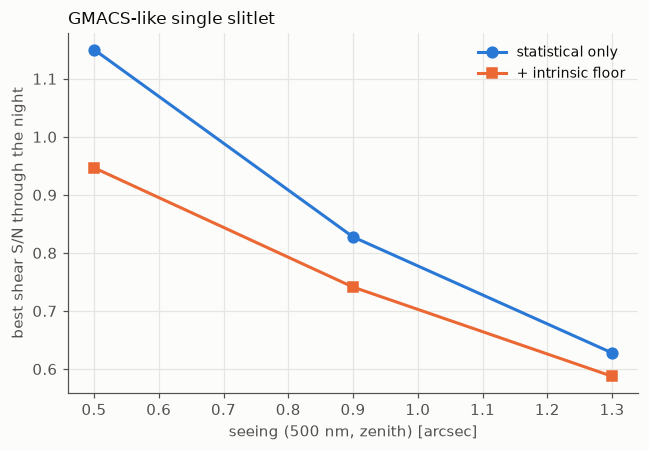

In [2]:
Z = 0.35
galaxy = DiscGalaxy(r_e=1.2, inc=55.0, pa=30.0, v_flat=180.0, z=Z, sigma0=30.0)
flux = 3e-15 * u.erg / u.s / u.cm**2
target = ForecastTarget(coord, galaxy, flux, "OII3727", name="single slitlet")
print(f"[O II] observed at {target.observed_wavelength.to(u.nm):.1f}")

seeing_grid = np.array([0.5, 0.9, 1.3]) * u.arcsec
t0 = time.time()
f = forecast_slit(
    gmacs, target, night, lib, g=G, seeing_ref=seeing_grid, solar_flux=F107,
    site=GMT, time_step=90 * u.min, intrinsic_sigma=FLOOR,
)  # fmt: skip
print(f"done in {time.time() - t0:.0f} s")

best_stat = np.nanmax(f.shear_snr_stat, axis=0)
best_tot = np.nanmax(f.shear_snr, axis=0)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(seeing_grid.to_value(u.arcsec), best_stat, "o-", color=BLUE, label="statistical only")
ax.plot(seeing_grid.to_value(u.arcsec), best_tot, "s-", color=ORANGE, label="+ intrinsic floor")
ax.set_xlabel("seeing (500 nm, zenith) [arcsec]")
ax.set_ylabel("best shear S/N through the night")
ax.set_title("GMACS-like single slitlet")
ax.legend()
fig.tight_layout()

## 2. Survey-scale multiplex: a synthetic population of simultaneous slitlets

MANIFEST's real value is placing **many** slitlets on one GMT exposure at
once. KINO forecasts each slitlet independently (no shared-detector/overlap
model -- see the limitations below) and combines the results: the per-galaxy
shear precisions add like independent measurements, so the *survey*
precision on a stack of $N_\mathrm{det}$ detected galaxies is
$\sigma_\mathrm{survey} = \sigma_\mathrm{typical} / \sqrt{N_\mathrm{det}}$.

15 simultaneous slitlets forecast in 136 s
detectable (stat S/N >= 3): 7/15
typical per-galaxy sigma_g1 (statistical): 0.0059
stacked survey-level sigma_g1 (7 galaxies): 0.0022


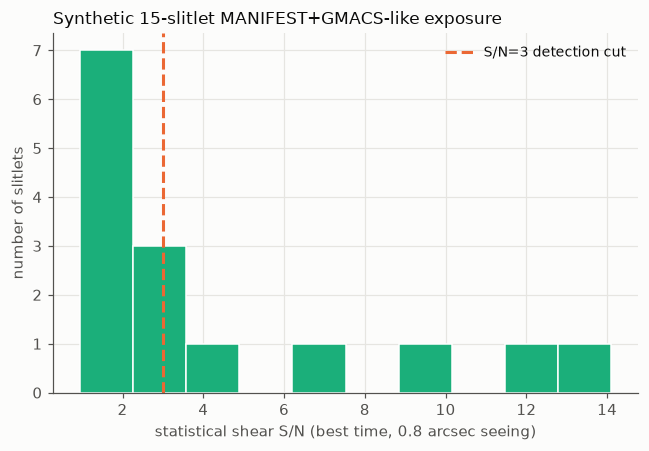

In [3]:
rng = np.random.default_rng(14)
flux_unit = u.erg / u.s / u.cm**2
n_targets = 15
catalogue = []
for i in range(n_targets):
    # z fixed at 0.35 (not swept): [O II] only lands in gmacs.yaml's own
    # narrow 500-520 nm demo window for z in ~0.342-0.395 -- a real MOS
    # mask would be designed around one line/redshift slice this way too.
    gal = DiscGalaxy(
        r_e=float(rng.uniform(0.8, 2.5)),
        inc=float(rng.uniform(35, 80)),
        pa=float(rng.uniform(0, 180)),
        v_flat=float(rng.uniform(120, 220)),
        z=0.35,
        sigma0=30.0,
    )
    pos = SkyCoord(f"{rng.uniform(19.3, 20.1):.3f}h", f"{rng.uniform(-20, -18):.2f}d")
    flux_i = float(10 ** rng.uniform(-13.0, -11.5)) * flux_unit
    catalogue.append(ForecastTarget(pos, gal, flux_i, "OII3727", name=f"S{i + 1}"))

t0 = time.time()
stat_snr = []
for t in catalogue:
    try:
        f_i = forecast_slit(
            gmacs, t, night, lib, g=G, seeing_ref=[0.8] * u.arcsec, solar_flux=F107,
            site=GMT, time_step=90 * u.min,
        )  # fmt: skip
        stat_snr.append(float(np.nanmax(f_i.shear_snr_stat[:, 0])))
    except ValueError:
        stat_snr.append(np.nan)
stat_snr = np.array(stat_snr)
print(f"{n_targets} simultaneous slitlets forecast in {time.time() - t0:.0f} s")

detected = np.isfinite(stat_snr) & (stat_snr >= 3.0)
print(f"detectable (stat S/N >= 3): {detected.sum()}/{n_targets}")
sigma_typical = 1.0 / np.nanmedian(stat_snr[detected]) * np.abs(G[0])
sigma_survey = sigma_typical / np.sqrt(max(detected.sum(), 1))
print(f"typical per-galaxy sigma_g1 (statistical): {sigma_typical:.4f}")
print(f"stacked survey-level sigma_g1 ({detected.sum()} galaxies): {sigma_survey:.4f}")

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.hist(stat_snr[np.isfinite(stat_snr)], bins=10, color=AQUA, edgecolor="white")
ax.axvline(3.0, color=ORANGE, ls="--", label="S/N=3 detection cut")
ax.set_xlabel("statistical shear S/N (best time, 0.8 arcsec seeing)")
ax.set_ylabel("number of slitlets")
ax.set_title(f"Synthetic {n_targets}-slitlet MANIFEST+GMACS-like exposure")
ax.legend()
fig.tight_layout()

## Known limitations (carry into any real MANIFEST+GMACS use)

- **Not a real multi-object simulation.** Each slitlet above is forecast as
  an independent single-slit exposure -- no shared detector, no overlapping
  spectral traces, no fibre-positioner collision/yield model, and no mask
  design constraint on how close two targets can be placed. `gmacs.yaml`'s
  own header already states this scope limit.
- **`gmacs.yaml` is fiducial**, not GMACS's as-built specification (resolving
  power, throughput, detector -- see the config's own header).
- The synthetic 25-target population is illustrative (seeded, reproducible),
  not drawn from any real catalogue or candidate list.
- `FLOOR = 0.024` reuses the Gurri, Taylor & Fluke (2021) literature value
  (`notebooks/data/phase6_ensemble.json`'s own `benchmark` entry), not a
  GMACS-specific measurement.